# 04 — Model Comparison
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 5**:
- Try **Decision Tree** and **Random Forest** regressors
- Compare their **test R²** against the baseline (Linear Regression, R² ≈ 0.68)
- Document how each model behaves (strengths / weaknesses)
- **Deliverable:** this notebook

## Setup

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as in 01, 02 and 03) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

## 1. Load the train and test data from Week 3
Same files as Week 4, so all models are compared on exactly the same data.
- **Train** = March 2025 – March 2026 (X = 13 months)
- **Test** = April 2026

In [2]:
train = pd.read_csv(os.path.join(path, "train_data.csv"))
test = pd.read_csv(os.path.join(path, "test_data.csv"))

print("Training rows:", len(train), "| months:", train["Month"].min(), "to", train["Month"].max())
print("Test rows:    ", len(test), "| month:", test["Month"].unique()[0])

Training rows: 140798 | months: 2025-03 to 2026-03
Test rows:     12465 | month: 2026-04


## 2. Prepare the data (same as Week 3 and 4)
Same `prepare()` function as before, with **one addition: `Latitude` and `Longitude`** (the map coordinates of each home). Tree models can split on coordinates ("is the home west of longitude −118.4?"), which lets them carve out neighborhoods much more precisely than county and city alone. All three models get the same inputs, including the Linear Regression.

Tree models don't actually *need* scaling or logs of the features, since they only split values into "bigger than" / "smaller than". But keeping the exact same inputs makes the comparison fair: the only thing that changes is the model.

In [3]:
number_cols = ["Latitude", "Longitude", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["Latitude", "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]


def prepare(train, test):
    train = train.copy()
    test = test.copy()

    # 1. Missing values
    for col in flag_cols:                          # flag first (before filling)
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in number_cols:                        # fill with TRAINING median
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding: keep cities with 100+ training sales, the rest become "Other"
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = number_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns as train

    # 4. Normalize number columns with TRAINING mean and std
    for col in number_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = prepare(train, test)
actual_price = np.exp(y_test)
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

KeyError: 'Latitude'

## 3. A helper to score each model
Every model predicts **log(price)**, so I turn predictions back into dollars with `np.exp()` and calculate:
- **R² (dollars)**: the official metric
- **R² (log price)**
- **MAE**: average dollar error
- **R² without the top/bottom 0.5% of prices**: same check as Week 4, to see how much the extreme homes matter

In [ ]:
low = train["ClosePrice"].quantile(0.005)
high = train["ClosePrice"].quantile(0.995)
middle = (actual_price >= low) & (actual_price <= high)

results = []

def score(name, pred_log, seconds):
    pred_price = np.exp(pred_log)
    results.append({
        "model": name,
        "test R2": r2_score(actual_price, pred_price),
        "test R2 (log)": r2_score(y_test, pred_log),
        "MAE ($)": mean_absolute_error(actual_price, pred_price),
        "R2 w/o top/bottom 0.5%": r2_score(actual_price[middle], pred_price[middle]),
        "train time (s)": seconds,
    })
    print(name, "-> test R²:", round(results[-1]["test R2"], 4))

## 4. Baseline: Linear Regression (from Week 4)
I retrain it here so all the models are in one table.

In [ ]:
start = time.time()
lr = LinearRegression()
lr.fit(X_train, y_train)
score("Linear Regression (baseline)", lr.predict(X_test), time.time() - start)

Linear Regression (baseline) -> test R²: 0.6755


## 5. Decision Tree
A decision tree asks a series of yes/no questions (for example "is living area > 2,000 sq ft?" then "is the city Irvine?") and predicts the average price of the homes that end up in the same "leaf".

The most important setting is **`max_depth`**, how many questions deep the tree can go:
- too shallow: the tree is too simple (**underfitting**)
- too deep: the tree memorizes the training data (**overfitting**)

### Choosing max_depth
Like choosing X in Week 3, I **don't** tune on the test month. I train on March 2025 – February 2026 and check each depth on **March 2026** (the validation month).

In [ ]:
fit_part = train[train["Month"] < "2026-03"]
val_part = train[train["Month"] == "2026-03"]
X_fit, X_val, y_fit, y_val = prepare(fit_part, val_part)

depth_results = []
for depth in [5, 10, 15, 20, 25, None]:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=42)
    tree.fit(X_fit, y_fit)
    train_r2 = r2_score(np.exp(y_fit), np.exp(tree.predict(X_fit)))
    val_r2 = r2_score(np.exp(y_val), np.exp(tree.predict(X_val)))
    depth_results.append({"max_depth": str(depth), "train R2": train_r2, "validation R2": val_r2})

depth_results = pd.DataFrame(depth_results)
depth_results

,max_depth,train R2,validation R2
0,5,0.5349,0.5290
1,10,0.7984,0.7425
2,15,0.8818,0.7752
3,20,0.9027,0.7796
4,25,0.9104,0.7856
5,None,0.9172,0.7882


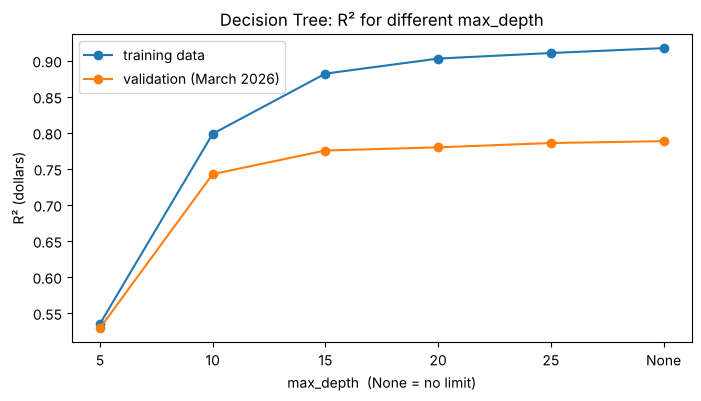

Best max_depth: None


In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(depth_results["max_depth"], depth_results["train R2"], marker="o", label="training data")
plt.plot(depth_results["max_depth"], depth_results["validation R2"], marker="o", label="validation (March 2026)")
plt.title("Decision Tree: R² for different max_depth")
plt.xlabel("max_depth  (None = no limit)")
plt.ylabel("R² (dollars)")
plt.legend()
plt.show()

best_depth = depth_results.loc[depth_results["validation R2"].idxmax(), "max_depth"]
best_depth = None if best_depth == "None" else int(best_depth)
print("Best max_depth:", best_depth)

**What I notice:**
- With a shallow tree (depth 5), both training and validation R² are low (~0.53). The tree is too simple (**underfitting**).
- As the tree gets deeper, training R² keeps climbing to about **0.92**, but validation R² levels off around **0.78–0.79**. That growing gap between the two lines is **overfitting**: the tree starts memorizing the training homes.
- Validation R² is highest with no depth limit, so I use `max_depth=None`. `min_samples_leaf=5` still stops it from going all the way down to single homes.

### Train the final Decision Tree and test it on April 2026

In [ ]:
start = time.time()
tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=42)
tree.fit(X_train, y_train)
score("Decision Tree (max_depth=" + str(best_depth) + ")", tree.predict(X_test), time.time() - start)

Decision Tree (max_depth=None) -> test R²: 0.7464


## 6. Random Forest
A random forest builds **many decision trees** (here 100), each one on a random sample of the homes and a random subset of the columns, and then **averages** their predictions. Averaging many different trees cancels out a lot of their individual mistakes, so a forest usually beats a single tree.

Settings I use:
- `n_estimators=100`: number of trees
- `min_samples_leaf=3`: each leaf needs at least 3 homes (stops trees from memorizing single homes)
- `max_features=0.3`: each split looks at a random 30% of the columns, which makes the trees more different from each other
- `n_jobs=-1`: use all CPU cores so it trains faster

*This cell can take a few minutes.*

In [ ]:
start = time.time()
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.3,
                               n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
score("Random Forest (100 trees)", forest.predict(X_test), time.time() - start)

Random Forest (100 trees) -> test R²: 0.7422


## 7. Compare the models

In [ ]:
results_df = pd.DataFrame(results).set_index("model")
results_df

,test R2,test R2 (log),MAE ($),R2 w/o top/bottom 0.5%,train time (s)
model,,,,,
Linear Regression (baseline),0.6755,0.8676,"262,585.5956",0.7929,5.1027
Decision Tree (max_depth=None),0.7464,0.8818,"239,587.7941",0.7978,6.5419
Random Forest (100 trees),0.7422,0.9160,"206,760.6529",0.8577,81.1147


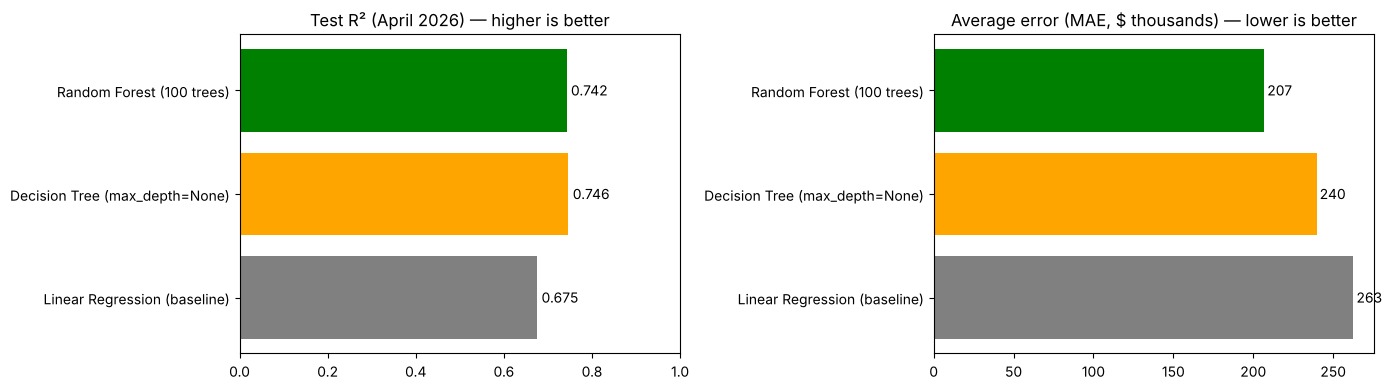

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].barh(results_df.index, results_df["test R2"], color=["gray", "orange", "green"])
axes[0].set_title("Test R² (April 2026) — higher is better")
axes[0].set_xlim(0, 1)
for i, v in enumerate(results_df["test R2"]):
    axes[0].text(v + 0.01, i, round(v, 3), va="center")

axes[1].barh(results_df.index, results_df["MAE ($)"] / 1000, color=["gray", "orange", "green"])
axes[1].set_title("Average error (MAE, $ thousands) — lower is better")
for i, v in enumerate(results_df["MAE ($)"] / 1000):
    axes[1].text(v + 2, i, round(v), va="center")

plt.tight_layout()
plt.show()

**What I notice:**
- **Both tree models beat the baseline.** Test R² goes from **0.68** (Linear Regression) to about **0.75** (Decision Tree) and **0.74** (Random Forest).
- On R² in dollars the Decision Tree and Random Forest are basically **tied**, but the **Random Forest is clearly better on everything else**: lowest average error (**$207K vs $240K vs $263K**), best R² on log price (**0.92**), and best R² once the extreme homes are left out (**0.86**).
- The forest's dollar R² is held back by a few very expensive homes. Averaging 100 trees makes its predictions "play it safe", so it tends to under-predict the most expensive homes, and those errors are huge in dollars.
- Linear Regression is slightly different from Week 4 (0.6755 vs 0.6764) because it now also gets latitude/longitude; for a straight-line model, coordinates barely help.
- The forest takes much longer to train (~1–2 minutes vs a few seconds).

## 8. Predicted vs actual for each model

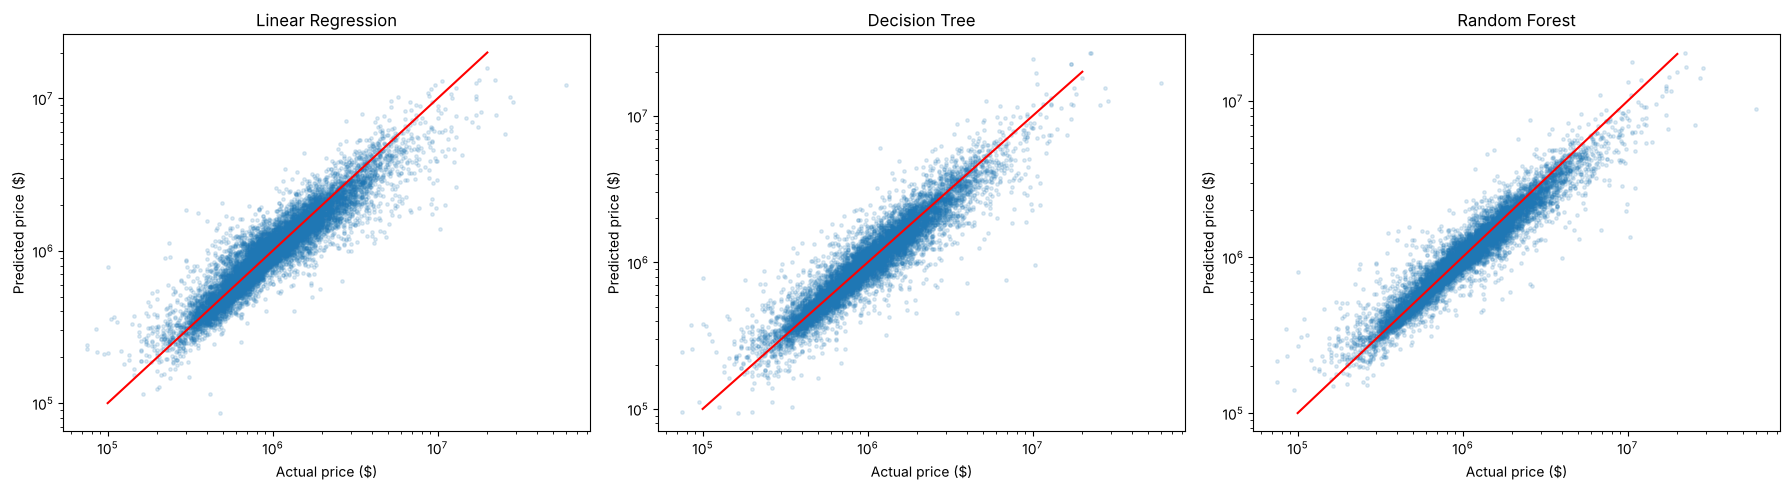

In [ ]:
models = {"Linear Regression": lr, "Decision Tree": tree, "Random Forest": forest}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, m) in zip(axes, models.items()):
    pred_price = np.exp(m.predict(X_test))
    ax.scatter(actual_price, pred_price, alpha=0.15, s=6)
    ax.plot([1e5, 2e7], [1e5, 2e7], color="red")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual price ($)")
    ax.set_ylabel("Predicted price ($)")
plt.tight_layout()
plt.show()

**What I notice:** all three follow the red line, but the **Random Forest's cloud is the tightest**, meaning its predictions are the most consistent. The Decision Tree's predictions look more "blocky", because every home in the same leaf gets exactly the same price. The Linear Regression cloud is the widest.

## 9. Which features does the Random Forest use most?
Random forests give a **feature importance** score: how much each column helped the trees reduce their error. Higher = more useful.

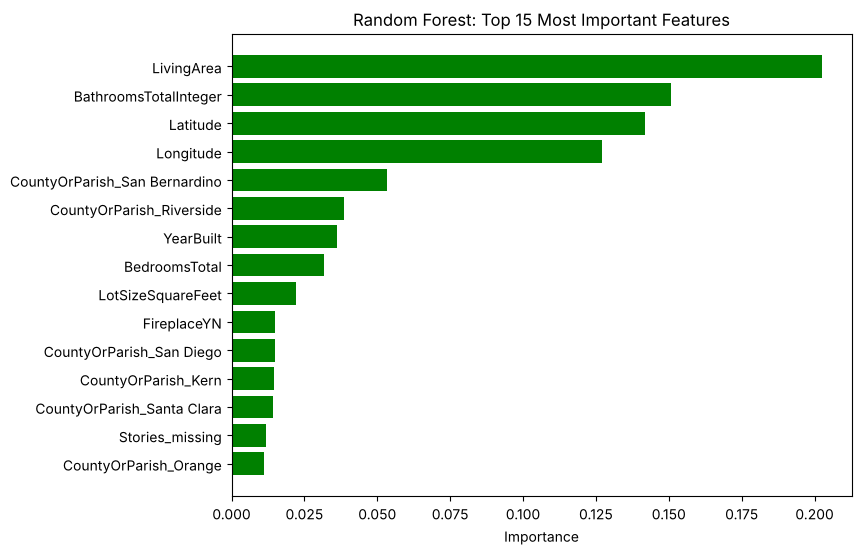

In [ ]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top15 = importance.head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15.values[::-1], color="green")
plt.title("Random Forest: Top 15 Most Important Features")
plt.xlabel("Importance")
plt.show()

**What I notice:**
- **Living area** is the most important feature, then **bathrooms**.
- **Latitude and longitude** are the 3rd and 4th most important. The forest uses the map coordinates to find expensive and cheap neighborhoods, which is why adding them helped so much.
- Some **county** columns (San Bernardino, Riverside) are also important. These are big, cheaper inland counties, so "is this home in San Bernardino?" is a useful early split.
- This matches Week 2: size and location drive price.

## 10. Save the results

In [ ]:
results_df.to_csv(os.path.join(path, "model_comparison_results.csv"))
print("Saved model_comparison_results.csv")

Saved model_comparison_results.csv


---
## Summary

| Model | Test R² ($) | Test R² (log) | MAE | Train time |
|---|---|---|---|---|
| Linear Regression (baseline) | 0.68 | 0.87 | ≈ $263K | ~5 s |
| Decision Tree | **0.75** | 0.88 | ≈ $240K | ~7 s |
| Random Forest (100 trees) | 0.74 | **0.92** | **≈ $207K** | ~1–2 min |

### How each model behaves
| Model | Strengths | Weaknesses |
|---|---|---|
| **Linear Regression** | Fast, simple, easy to explain (one coefficient per feature) | Assumes every feature adds the same amount everywhere; can't use map coordinates well |
| **Decision Tree** | Can find neighborhoods and "if this, then that" rules; easy to picture | Overfits easily (training R² 0.92 vs validation 0.79); "blocky" predictions; small data changes can change the whole tree |
| **Random Forest** | Most accurate overall (lowest error, best log R²); averaging many trees reduces overfitting; shows feature importance | Slower to train; harder to explain; tends to under-predict the most expensive homes |

**Takeaways:**
1. Both tree models **beat the baseline** (0.68 → ~0.74–0.75).
2. **Random Forest** is the best model overall: lowest average error and best accuracy on typical homes.
3. **Location detail** (latitude/longitude) matters a lot for tree models.
4. The biggest remaining problem is still the **very expensive homes**.

**Next (Week 6):** feature engineering, for example bed/bath ratio, age of the home, and a school-district location layer. Then re-train these models.